In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
N = 100000

In [3]:
def terminal_price(Z, S0, T, r, sigma):
    return S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)

In [4]:
def option_payoff(St, K, option):

    if option == "call":
        return np.maximum(St - K, 0)
    elif option == "put":
        return np.maximum(K - St, 0)
    else:
        raise ValueError("Option bust be 'call' or 'put'")
    

## 1. Standard Monte Carlo Pricing

Under risk-neutral GBM, terminal stock prices are simulated using

$$
S_T=S_0e^{(r-\sigma^2/2)T+\sigma\sqrt{T}Z},\qquad Z\sim N(0,1).
$$

European call and put prices are estimated by averaging and discounting simulated payoffs:

$$
\hat V_N=e^{-rT}\frac1N\sum_{i=1}^N f(S_T^{(i)}).
$$

The estimator is unbiased and converges to the true option price as $N\to\infty$. Its uncertainty is quantified using the estimated standard error and an approximate 95% confidence interval:

$$
\hat V_N\pm1.96\widehat{SE}.
$$

Estimates are validated against  put-call parity.

### 1.1. European Call & Put Pricing

In [5]:
rng = np.random.default_rng(7)

Z = rng.normal(0, 1, N)
St = terminal_price(Z, S0, T, r, sigma)

call_payoff = option_payoff(St, K, "call")
put_payoff = option_payoff(St, K, "put")

call_price = np.exp(-r*T) * np.mean(call_payoff)
put_price = np.exp(-r*T) * np.mean(put_payoff)

print("Call Price:", call_price)
print("Put Price:", put_price)

Call Price: 10.40666378166819
Put Price: 5.5641383356515215


In [6]:
lhs = call_price - put_price
rhs = S0 - K * np.exp(-r*T)

parity_error = abs(lhs - rhs)

print("LHS:", lhs)
print("RHS:", rhs)
print("Parity Error:", parity_error)

LHS: 4.842525446016668
RHS: 4.877057549928594
Parity Error: 0.03453210391192574


### 1.2. Standard Errors & Confidence Intervals

In [7]:
c = 0.95
s = - norm.ppf((1 - c) / 2).round(3)
print(s)

1.96


In [8]:
for option, payoffs in [("Call", call_payoff), ("Put", put_payoff)]:

    price = np.exp(-r * T) * np.mean(payoffs)

    sigma_estimate = np.std(payoffs, ddof = 1)
    SE_estimate = np.exp(-r * T) * sigma_estimate / np.sqrt(N)

    CI = [price - 1.96 * SE_estimate, price + 1.96 * SE_estimate]

## 2. Monte Carlo Convergence

Monte Carlo convergence is assessed by comparing simulated prices against the analytical Black–Scholes value for increasing sample sizes.

The Central Limit Theorem gives the theoretical RMSE:

$$
\operatorname{RMSE}=\frac{\sigma_X}{\sqrt N}=O(N^{-1/2}).
$$

Empirical RMSE is estimated across $M$ independent experiments:

$$
\widehat{\operatorname{RMSE}}(N)=\sqrt{\frac1M\sum_{j=1}^M(\hat V_N^{(j)}-V_{BS})^2}.
$$

### 2.1. Black-Scholes Price Comparison

In [9]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

In [10]:
def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [11]:
bs_price, _ = black_scholes_price(S0, K, T, r, sigma)
print(bs_price)

10.450583572185565


### 2.2. Price & RMSE Convergence

In [12]:
n_values = np.logspace(2, 5, 50, dtype=int)
rng = np.random.default_rng(4)
M = 100

errors = []
estimates = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M,n))
    St = terminal_price(Z, S0, T, r, sigma)
    payoffs = option_payoff(St, K, "call")

    prices = np.exp(-r*T) * np.mean(payoffs, axis = 1)
    
    estimates.append(np.mean(prices))
    errors.append(np.sqrt(np.mean((prices - bs_price)**2)))

reference = np.exp(-r*T) * np.std(payoffs, ddof=1) / np.sqrt(n_values)


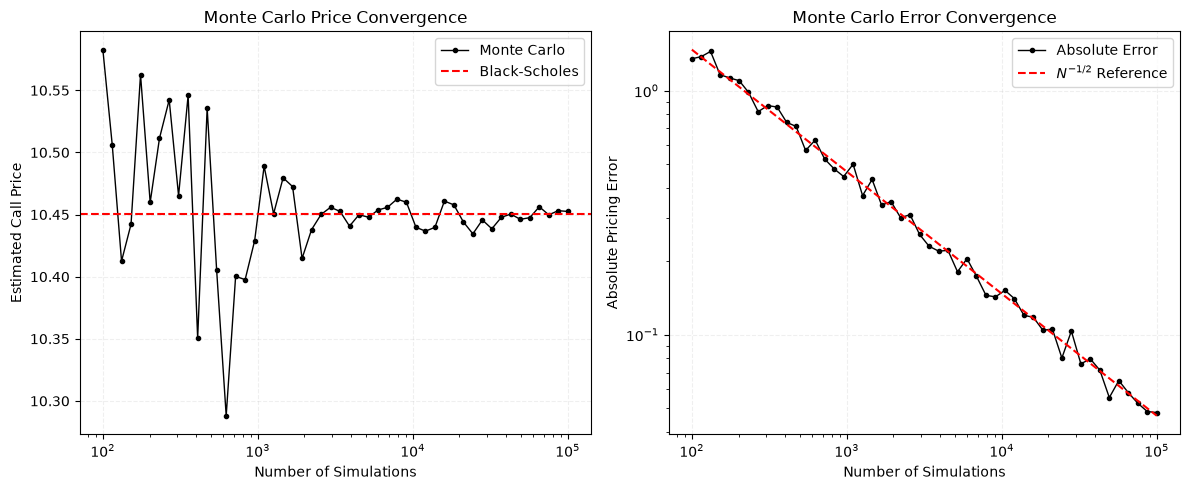

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Monte Carlo price convergence
axs[0].plot(n_values, estimates, color="black",
            linewidth = 1, marker = ".", label = "Monte Carlo")

axs[0].axhline(bs_price, color="red",
               linestyle = "--", label = "Black-Scholes")

axs[0].set_xscale("log")
axs[0].set_xlabel("Number of Simulations")
axs[0].set_ylabel("Estimated Call Price")
axs[0].set_title("Monte Carlo Price Convergence")
axs[0].legend()
axs[0].grid(alpha = 0.2, linestyle = "--")

# Absolute pricing error
axs[1].plot(n_values, errors, color = "black",
            linewidth = 1, marker = ".", label = "Absolute Error")

axs[1].plot(n_values, reference, color = "red",
            linestyle = "--", linewidth = 1.5,
            label = r"$N^{-1/2}$ Reference")

axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlabel("Number of Simulations")
axs[1].set_ylabel("Absolute Pricing Error")
axs[1].set_title("Monte Carlo Error Convergence")
axs[1].grid(True, which = "major", alpha = 0.2, linestyle = "--")
axs[1].legend()

plt.tight_layout()
plt.show()


The results illustrate convergence towards Black–Scholes, with sampling fluctuations and decreasing estimation error.

## 3. Variance Reduction

### 3.1. Antithetic Variates in Monte Carlo

Antithetic variates reduce estimation variance by pairing each normal sample $Z_i$ with $-Z_i$.

The paired payoff is

$$
A_i=\frac{f(S_T^{(+Z_i)})+f(S_T^{(-Z_i)})}{2}.
$$

The negative covariance between paired payoffs reduces the variance of their average without changing its expectation.

In [19]:
n_values = np.unique(2 * (np.logspace(2, 5, 50, dtype=int) // 2))
rng = np.random.default_rng(4)
M = 100

errors_antithetic = []
estimates_antithetic = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M, n//2))

    Stx = terminal_price(Z, S0, T, r, sigma)
    Sty = terminal_price(-Z, S0, T, r, sigma)

    x = option_payoff(Stx, K, "call")
    y = option_payoff(Sty, K, "call")

    A = (x + y) / 2

    prices = np.exp(-r*T) * np.mean(A, axis = 1)

    estimates_antithetic.append(np.mean(prices))
    errors_antithetic.append(np.sqrt(np.mean((prices - bs_price)**2)))

### 3.2. Control Variates in Monte Carlo

Control variates exploit a correlated variable with a known expectation to reduce estimation error.

Using the discounted terminal stock price as the control,

$$
\hat V_{CV}=\bar X+\hat\beta(S_0-\bar Y),
$$

where

$$
\hat\beta=\frac{\widehat{\operatorname{Cov}}(X,Y)}{\widehat{\operatorname{Var}}(Y)}.
$$

The coefficient is estimated using an independent pilot sample. The adjustment reduces variance by exploiting the correlation between stock prices and option payoffs.

In [15]:
rng = np.random.default_rng(4)

# Estimate beta using an independent pilot sample
Z_pilot = rng.normal(0, 1, 50000)

St_pilot = terminal_price(Z_pilot, S0, T, r, sigma)

X_pilot = np.exp(-r * T) * option_payoff(St_pilot, K, "call")
Y_pilot = np.exp(-r * T) * St_pilot

beta = np.cov(X_pilot, Y_pilot)[0, 1] / np.var(Y_pilot, ddof=1)

# Control variate simulation
errors_control = []
estimates_control = []

for n in n_values:

    Z = rng.normal(0, 1, (M, n))

    St = terminal_price(Z, S0, T, r, sigma)

    X = np.exp(-r * T) * option_payoff(St, K, "call")
    Y = np.exp(-r * T) * St

    prices = np.mean(X, axis = 1) + beta * (S0 - np.mean(Y, axis = 1))

    estimates_control.append(np.mean(prices))
    errors_control.append(np.sqrt(np.mean((prices - bs_price) ** 2)))

### 3.3. Comparison of Variance Reduction Methods

The three estimators are compared using empirical RMSE across identical simulation counts.

Efficiency improvements are quantified by the empirical MSE reduction factor:

$$
R=\frac{\widehat{\operatorname{MSE}}_{\mathrm{standard}}}{\widehat{\operatorname{MSE}}_{\mathrm{reduced}}}.
$$

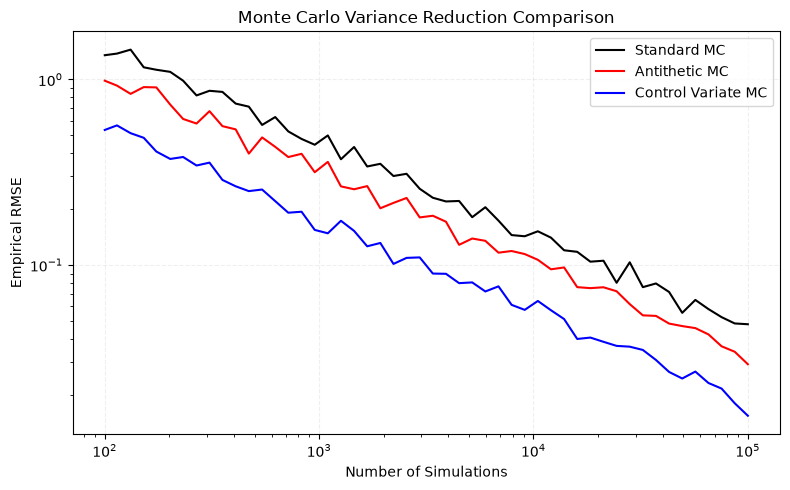

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(n_values, errors,
         color="black", linewidth=1.5,
         label="Standard MC")

plt.plot(n_values, errors_antithetic,
         color="red", linewidth=1.5,
         label="Antithetic MC")

plt.plot(n_values, errors_control,
         color="blue", linewidth=1.5,
         label="Control Variate MC")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("Empirical RMSE")
plt.title("Monte Carlo Variance Reduction Comparison")

plt.grid(True, which="major", alpha=0.2, linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
idx = np.argmin(np.abs(n_values - 10000))

factor_antithetic = (errors[idx] / errors_antithetic[idx])**2
factor_control = (errors[idx] / errors_control[idx])**2

print("Antithetic Variate MSE Reduction:", factor_antithetic)
print("Control Variate MSE Reduction:", factor_control)

Antithetic Variate MSE Reduction: 2.029256304780452
Control Variate MSE Reduction: 5.63328886162021



Both variance-reduction methods lower estimation error, with control variates demonstrating the greater improvement in these experiments.